In [14]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Project paths
PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data" / "images"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Image directory exists:", DATA_DIR.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())

PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU
Image directory exists: True
Processed directory exists: True


In [15]:
train_df = pd.read_csv(PROCESSED_DIR / "train_metadata.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation_metadata.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_metadata.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Total samples:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining columns:", train_df.columns.tolist())
print("Sample training rows:")
display(train_df.head())

Training samples: 39236
Validation samples: 4360
Test samples: 10704
Total samples: 54300

Training columns: ['image_path', 'label']
Sample training rows:


,image_path,label
0,E:\PlantVillage\data\images\Soybean___healthy\...,Soybean___healthy
1,E:\PlantVillage\data\images\Tomato___Late_blig...,Tomato___Late_blight
2,E:\PlantVillage\data\images\Potato___healthy\b...,Potato___healthy
3,E:\PlantVillage\data\images\Grape___Leaf_bligh...,Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
4,E:\PlantVillage\data\images\Grape___Esca_(Blac...,Grape___Esca_(Black_Measles)


In [16]:
IMAGE_SIZE = 224
BATCH_SIZE = 16

# Training images: augmentation enabled
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test: deterministic transformations only
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image size:", IMAGE_SIZE, "×", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training augmentation: enabled")
print("Validation/test augmentation: disabled")

Image size: 224 × 224
Batch size: 16
Training augmentation: enabled
Validation/test augmentation: disabled


In [17]:
class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform, class_to_idx):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = self.class_to_idx[row["label"]]

        return image, label


# Use one consistent mapping for all three splits
classes = sorted(train_df["label"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

train_dataset = PlantVillageDataset(
    train_df, train_transform, class_to_idx
)
val_dataset = PlantVillageDataset(
    val_df, eval_transform, class_to_idx
)
test_dataset = PlantVillageDataset(
    test_df, eval_transform, class_to_idx
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Classes:", len(classes))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Classes: 38
Training samples: 39236
Validation samples: 4360
Test samples: 10704


In [11]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("All image values finite:", torch.isfinite(images).all().item())
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (BATCH_SIZE, 3, 224, 224)
assert labels.shape == (BATCH_SIZE,)
assert torch.isfinite(images).all()
assert labels.min().item() >= 0
assert labels.max().item() < len(classes)

print("\nAll batch checks passed!")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image data type: torch.float32
Label data type: torch.int64
All image values finite: True
Label range: 3 to 37

All batch checks passed!


In [18]:
class PlantDiseaseCNN(nn.Module):
    def __init__(self, num_classes=38):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 -> 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 -> 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 -> 128
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 4: 128 -> 256
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Reduce each feature map to one value
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = PlantDiseaseCNN(num_classes=len(classes)).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(model)
print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model device:", next(model.parameters()).device)

PlantDiseaseCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): Batch

In [13]:
model.eval()

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Expected output shape:", (BATCH_SIZE, len(classes)))
print("Output contains only finite values:", torch.isfinite(outputs).all().item())

assert outputs.shape == (BATCH_SIZE, 38)
assert torch.isfinite(outputs).all()

print("\nForward-pass test passed!")

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 38])
Expected output shape: (16, 38)
Output contains only finite values: True

Forward-pass test passed!


In [14]:
print("Model:", type(model).__name__)
print("Device:", next(model.parameters()).device)
print("Number of classes:", len(classes))
print("Total parameters:", sum(p.numel() for p in model.parameters()))

model.eval()
images, labels = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Output shape:", outputs.shape)
print("All outputs finite:", torch.isfinite(outputs).all().item())

assert outputs.shape == (16, 38)
assert torch.isfinite(outputs).all()

print("\nAll model checks passed!")

Model: PlantDiseaseCNN
Device: cuda:0
Number of classes: 38
Total parameters: 399142
Output shape: torch.Size([16, 38])
All outputs finite: True

All model checks passed!


In [15]:
import copy
import time
from pathlib import Path

# Training configuration
EPOCHS = 15
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
PATIENCE = 4

# Save model checkpoints and training history
MODEL_DIR = PROJECT_DIR / "models" / "custom_cnn"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Device:", device)
print("Epoch limit:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Early-stopping patience:", PATIENCE)
print("Checkpoint path:", BEST_MODEL_PATH)
print("Loss function:", type(criterion).__name__)
print("Optimizer:", type(optimizer).__name__)
print("Scheduler:", type(scheduler).__name__)

Device: cuda
Epoch limit: 15
Learning rate: 0.001
Weight decay: 0.0001
Early-stopping patience: 4
Checkpoint path: E:\PlantVillage\models\custom_cnn\best_model.pth
Loss function: CrossEntropyLoss
Optimizer: Adam
Scheduler: ReduceLROnPlateau


In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start = time.time()

    for batch_idx, (images, labels) in enumerate(loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Batch {batch_idx + 1}/{len(loader)} | "
                f"Loss: {running_loss / total:.4f} | "
                f"Time: {(time.time() - start) / 60:.1f} min",
                flush=True
            )

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total


print("Training and validation functions defined successfully.")

Training and validation functions defined successfully.


In [17]:
import time
import torch

# Use a small subset for the performance pilot
pilot_batches = 200

model.train()
running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

for batch_idx, (images, labels) in enumerate(train_loader):
    if batch_idx >= pilot_batches:
        break

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True)
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)
    running_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

    if (batch_idx + 1) % 25 == 0:
        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.time() - start_time
        print(
            f"Batch {batch_idx + 1}/{pilot_batches} | "
            f"Loss: {running_loss / total:.4f} | "
            f"Accuracy: {100 * correct / total:.2f}% | "
            f"Elapsed: {elapsed / 60:.2f} min",
            flush=True
        )

print("\nPilot completed.")
print(f"Images processed: {total}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.2f} min")

Batch 25/200 | Loss: 3.0470 | Accuracy: 21.25% | Elapsed: 0.28 min
Batch 50/200 | Loss: 2.9005 | Accuracy: 24.12% | Elapsed: 0.55 min
Batch 75/200 | Loss: 2.8139 | Accuracy: 25.92% | Elapsed: 0.80 min
Batch 100/200 | Loss: 2.7315 | Accuracy: 27.44% | Elapsed: 1.03 min
Batch 125/200 | Loss: 2.6568 | Accuracy: 29.65% | Elapsed: 1.26 min
Batch 150/200 | Loss: 2.5911 | Accuracy: 31.50% | Elapsed: 1.50 min
Batch 175/200 | Loss: 2.5417 | Accuracy: 32.36% | Elapsed: 1.74 min
Batch 200/200 | Loss: 2.5035 | Accuracy: 33.31% | Elapsed: 1.97 min

Pilot completed.
Images processed: 3200
Elapsed time: 1.98 min


In [18]:
import time
import torch

start_time = time.time()

train_loss, train_acc = train_one_epoch(
    model, train_loader, criterion, optimizer, device
)

val_loss, val_acc = evaluate(
    model, val_loader, criterion, device
)

scheduler.step(val_loss)

elapsed = time.time() - start_time

print(f"Training loss:      {train_loss:.4f}")
print(f"Training accuracy:  {train_acc * 100:.2f}%")
print(f"Validation loss:    {val_loss:.4f}")
print(f"Validation accuracy:{val_acc * 100:7.2f}%")
print(f"Time taken:         {elapsed / 60:.2f} minutes")
print(f"Learning rate:      {optimizer.param_groups[0]['lr']:.6f}")

Batch 100/2453 | Loss: 2.0049 | Time: 0.9 min
Batch 200/2453 | Loss: 1.9745 | Time: 1.8 min
Batch 300/2453 | Loss: 1.8973 | Time: 2.7 min
Batch 400/2453 | Loss: 1.8390 | Time: 3.6 min
Batch 500/2453 | Loss: 1.7874 | Time: 4.5 min
Batch 600/2453 | Loss: 1.7441 | Time: 5.3 min
Batch 700/2453 | Loss: 1.7027 | Time: 6.2 min
Batch 800/2453 | Loss: 1.6703 | Time: 7.1 min
Batch 900/2453 | Loss: 1.6298 | Time: 8.0 min
Batch 1000/2453 | Loss: 1.5946 | Time: 8.9 min
Batch 1100/2453 | Loss: 1.5595 | Time: 9.8 min
Batch 1200/2453 | Loss: 1.5335 | Time: 10.7 min
Batch 1300/2453 | Loss: 1.5003 | Time: 11.6 min
Batch 1400/2453 | Loss: 1.4827 | Time: 12.5 min
Batch 1500/2453 | Loss: 1.4591 | Time: 13.4 min
Batch 1600/2453 | Loss: 1.4369 | Time: 14.3 min
Batch 1700/2453 | Loss: 1.4165 | Time: 15.2 min
Batch 1800/2453 | Loss: 1.3938 | Time: 16.1 min
Batch 1900/2453 | Loss: 1.3757 | Time: 17.0 min
Batch 2000/2453 | Loss: 1.3578 | Time: 17.9 min
Batch 2100/2453 | Loss: 1.3399 | Time: 18.8 min
Batch 2200/2

In [19]:
import copy
import torch

# Restore the verified metrics from your first full epoch
first_val_loss = 0.3994
first_val_acc = 0.8883

history = {
    "train_loss": [0.7639],
    "train_acc": [0.7659],
    "val_loss": [first_val_loss],
    "val_acc": [first_val_acc],
}

best_val_loss = first_val_loss
best_model_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

# Save the current model checkpoint
torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": first_val_loss,
    "val_acc": first_val_acc,
    "class_to_idx": class_to_idx,
}, BEST_MODEL_PATH)

print("Initial best model saved:", BEST_MODEL_PATH)
print("Best validation loss:", best_val_loss)
print("Best validation accuracy:", f"{first_val_acc * 100:.2f}%")
print("Checkpoint exists:", BEST_MODEL_PATH.exists())

Initial best model saved: E:\PlantVillage\models\custom_cnn\best_model.pth
Best validation loss: 0.3994
Best validation accuracy: 88.83%
Checkpoint exists: True


In [20]:
names_to_check = [
    "model",
    "train_loader",
    "val_loader",
    "test_loader",
    "class_to_idx",
    "criterion",
    "optimizer",
    "scheduler",
    "device",
]

for name in names_to_check:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

model: available
train_loader: available
val_loader: available
test_loader: available
class_to_idx: available
criterion: available
optimizer: available
scheduler: available
device: available


In [21]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")

checkpoint_dir = PROJECT_DIR / "models" / "custom_cnn"
print("Checkpoint directory exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    checkpoints = list(checkpoint_dir.glob("*.pth"))
    print("Checkpoint files found:", len(checkpoints))

    for path in checkpoints:
        print(path.name, f"({path.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No checkpoint directory found.")

Checkpoint directory exists: True
Checkpoint files found: 1
best_model.pth (4.60 MB)


In [22]:
from pathlib import Path

checkpoint = Path(r"E:\PlantVillage\models\custom_cnn\best_model.pth")

print("Checkpoint exists:", checkpoint.exists())

if checkpoint.exists():
    print("Checkpoint size:", round(checkpoint.stat().st_size / (1024**2), 2), "MB")
else:
    print("No checkpoint found at this path.")

Checkpoint exists: True
Checkpoint size: 4.6 MB


In [23]:
import torch

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded successfully.")
print("Saved epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Validation accuracy:", checkpoint["val_acc"])
print("Model weights present:", "model_state_dict" in checkpoint)
print("Optimizer state present:", "optimizer_state_dict" in checkpoint)
print("Class mapping present:", "class_to_idx" in checkpoint)

Checkpoint loaded successfully.
Saved epoch: 1
Validation loss: 0.3994
Validation accuracy: 0.8883
Model weights present: True
Optimizer state present: True
Class mapping present: True


In [24]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

print("Model restored from checkpoint.")
print("Starting from saved epoch:", checkpoint["epoch"])
print("Validation accuracy:", f"{checkpoint['val_acc'] * 100:.2f}%")

Model restored from checkpoint.
Starting from saved epoch: 1
Validation accuracy: 88.83%


In [25]:

import copy
import time
import pandas as pd
import torch

MAX_EPOCHS = 15
PATIENCE = 4
start_epoch = 2

best_val_loss = float(checkpoint["val_loss"])
epochs_without_improvement = 0

history_rows = []

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    epoch_start = time.time()

    print(f"\n{'='*55}")
    print(f"Epoch {epoch}/{MAX_EPOCHS}")
    print(f"{'='*55}")

    # Train
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss: {running_loss / total:.4f}",
                flush=True
            )

    train_loss = running_loss / total
    train_acc = correct / total

    # Validate
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    # Update learning-rate scheduler
    scheduler.step(val_loss)

    elapsed = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]["lr"]

    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_acc * 100:.2f}%")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_acc * 100:.2f}%")
    print(f"Learning rate: {current_lr:.6f}")
    print(f"Epoch time: {elapsed / 60:.2f} minutes")

    history_rows.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": current_lr,
        "time_minutes": elapsed / 60,
    })

    # Save history after each epoch
    history_path = (
        BEST_MODEL_PATH.parent / "training_history.csv"
    )
    pd.DataFrame(history_rows).to_csv(history_path, index=False)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "class_to_idx": class_to_idx,
        }, BEST_MODEL_PATH)

        print("New best model saved!")
    else:
        epochs_without_improvement += 1
        print(
            f"No validation-loss improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nAdditional training finished.")
print("Best validation loss:", best_val_loss)
print("History saved to:", history_path)
print("Best checkpoint:", BEST_MODEL_PATH)



Epoch 2/15
Batch 100/2453 | Loss: 0.9598
Batch 200/2453 | Loss: 0.9121
Batch 300/2453 | Loss: 0.9028
Batch 400/2453 | Loss: 0.8849
Batch 500/2453 | Loss: 0.8798
Batch 600/2453 | Loss: 0.8769
Batch 700/2453 | Loss: 0.8715
Batch 800/2453 | Loss: 0.8677
Batch 900/2453 | Loss: 0.8544
Batch 1000/2453 | Loss: 0.8500
Batch 1100/2453 | Loss: 0.8405
Batch 1200/2453 | Loss: 0.8393
Batch 1300/2453 | Loss: 0.8388
Batch 1400/2453 | Loss: 0.8336
Batch 1500/2453 | Loss: 0.8243
Batch 1600/2453 | Loss: 0.8210
Batch 1700/2453 | Loss: 0.8133
Batch 1800/2453 | Loss: 0.8056
Batch 1900/2453 | Loss: 0.7981
Batch 2000/2453 | Loss: 0.7922
Batch 2100/2453 | Loss: 0.7867
Batch 2200/2453 | Loss: 0.7826
Batch 2300/2453 | Loss: 0.7769
Batch 2400/2453 | Loss: 0.7714
Train loss: 0.7685
Train accuracy: 76.28%
Validation loss: 0.3626
Validation accuracy: 89.27%
Learning rate: 0.001000
Epoch time: 13.83 minutes
New best model saved!

Epoch 3/15
Batch 100/2453 | Loss: 0.6966
Batch 200/2453 | Loss: 0.6730
Batch 300/2453 

In [26]:
from pathlib import Path
import pandas as pd
import torch

history_path = Path(r"E:\PlantVillage\models\custom_cnn\training_history.csv")
checkpoint_path = Path(r"E:\PlantVillage\models\custom_cnn\best_model.pth")

print("History file exists:", history_path.exists())
print("Best checkpoint exists:", checkpoint_path.exists())

if history_path.exists():
    history_df = pd.read_csv(history_path)
    display(history_df)
    print("\nEpochs recorded:", len(history_df))
    print("Best validation accuracy:",
          f"{history_df['val_accuracy'].max() * 100:.2f}%")
    print("Lowest validation loss:",
          f"{history_df['val_loss'].min():.4f}")

if checkpoint_path.exists():
    saved = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    print("\nBest checkpoint epoch:", saved["epoch"])
    print("Saved validation loss:", saved["val_loss"])
    print("Saved validation accuracy:",
          f"{saved['val_acc'] * 100:.2f}%")

History file exists: True
Best checkpoint exists: True


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,time_minutes
0,2,0.768501,0.762769,0.362615,0.892661,0.001,13.831432
1,3,0.568200,0.821643,0.293680,0.909174,0.001,12.450451
2,4,0.465124,0.855439,0.235036,0.927064,0.001,12.469462
3,5,0.390440,0.877383,0.247612,0.920642,0.001,12.471409
4,6,0.336054,0.896243,0.149124,0.952294,0.001,12.417054
5,7,0.301800,0.903711,0.145488,0.956193,0.001,12.477750
6,8,0.273105,0.913345,0.113179,0.964679,0.001,24.203893
7,9,0.248657,0.922826,0.124696,0.962615,0.001,12.590668
8,10,0.231452,0.926904,0.103556,0.968349,0.001,12.695481
9,11,0.215912,0.933276,0.122474,0.963532,0.001,12.635224



Epochs recorded: 14
Best validation accuracy: 98.03%
Lowest validation loss: 0.0700

Best checkpoint epoch: 13
Saved validation loss: 0.07004892420335544
Saved validation accuracy: 98.03%


In [28]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [1]:

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("BEST CHECKPOINT EPOCH:", checkpoint["epoch"])
print(f"Test accuracy:  {accuracy * 100:.2f}%")
print(f"Macro precision: {precision * 100:.2f}%")
print(f"Macro recall:    {recall * 100:.2f}%")
print(f"Macro F1-score:  {f1 * 100:.2f}%")
print("Test images:", len(all_labels))

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_to_idx))),
    target_names=[
        name for name, idx in sorted(
            class_to_idx.items(), key=lambda item: item[1]
        )
    ],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels, all_predictions,
    labels=list(range(len(class_to_idx)))
)

plt.figure(figsize=(18, 15))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("PlantVillage Test Confusion Matrix — Custom CNN")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()


NameError: name 'BEST_MODEL_PATH' is not defined

In [2]:
from pathlib import Path
import torch

PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data" / "images"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BEST_MODEL_PATH = (
    PROJECT_DIR / "models" / "custom_cnn" / "best_model.pth"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Checkpoint exists:", BEST_MODEL_PATH.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())

Device: cuda
Checkpoint exists: True
Processed directory exists: True


In [4]:
from pathlib import Path

notebook_dir = PROJECT_DIR

for path in notebook_dir.rglob("*.ipynb"):
    if "environment" not in str(path).lower():
        print(path)

In [5]:
from pathlib import Path

for root in [
    Path(r"E:\PlantVillage"),
    Path.home() / "Documents",
    Path.home() / "Desktop",
]:
    print(f"\nSearching: {root}")

    if root.exists():
        matches = list(root.glob("*.ipynb"))
        for path in matches:
            print("  ", path)

        if not matches:
            print("   No notebooks found directly in this folder.")


Searching: E:\PlantVillage
   No notebooks found directly in this folder.

Searching: C:\Users\ANUJA\Documents
   No notebooks found directly in this folder.

Searching: C:\Users\ANUJA\Desktop
   No notebooks found directly in this folder.


In [6]:
from pathlib import Path

NOTEBOOK_DIR = Path(r"E:\PlantVillage\notebook")

print("Notebook folder exists:", NOTEBOOK_DIR.exists())

for path in NOTEBOOK_DIR.rglob("*.ipynb"):
    print("Notebook found:", path)

Notebook folder exists: False


In [19]:
from pathlib import Path
import torch

PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data" / "images"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
BEST_MODEL_PATH = (
    PROJECT_DIR / "models" / "custom_cnn" / "best_model.pth"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Checkpoint exists:", BEST_MODEL_PATH.exists())

Device: cuda
Checkpoint exists: True


In [13]:
import torch

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation accuracy:", f"{checkpoint['val_acc'] * 100:.2f}%")
print("Model class available:", "PlantDiseaseCNN" in globals())
print("Training dataset available:", "train_dataset" in globals())
print("Test dataset available:", "test_dataset" in globals())
print("Test loader available:", "test_loader" in globals())

Checkpoint epoch: 13
Validation accuracy: 98.03%
Model class available: False
Training dataset available: True
Test dataset available: True
Test loader available: True


In [15]:
print("CNN class available:", "PlantDiseaseCNN" in globals())
print("Test loader available:", "test_loader" in globals())
print("Classes:", len(class_to_idx))

CNN class available: True
Test loader available: True
Classes: 38


In [20]:
import torch

# Recreate the model architecture
model = PlantDiseaseCNN(num_classes=len(class_to_idx)).to(device)

# Load the saved best checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model restored successfully!")
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {checkpoint['val_acc'] * 100:.2f}%")
print("Device:", device)
print("Test images:", len(test_dataset))

Model restored successfully!
Checkpoint epoch: 13
Validation accuracy: 98.03%
Device: cuda
Test images: 10704


FINAL TEST RESULTS
Test accuracy:  97.73%
Macro precision: 97.21%
Macro recall:    96.65%
Macro F1-score:  96.85%
Test images evaluated: 10704

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.95      0.98       127
                                 Apple___Black_rot       1.00      0.98      0.99       146
                          Apple___Cedar_apple_rust       0.98      0.96      0.97        52
                                   Apple___healthy       0.95      0.98      0.96       286
                               Blueberry___healthy       0.97      0.99      0.98       324
          Cherry_(including_sour)___Powdery_mildew       0.96      1.00      0.98       219
                 Cherry_(including_sour)___healthy       0.98      0.99      0.99       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.84      0.87       107
    

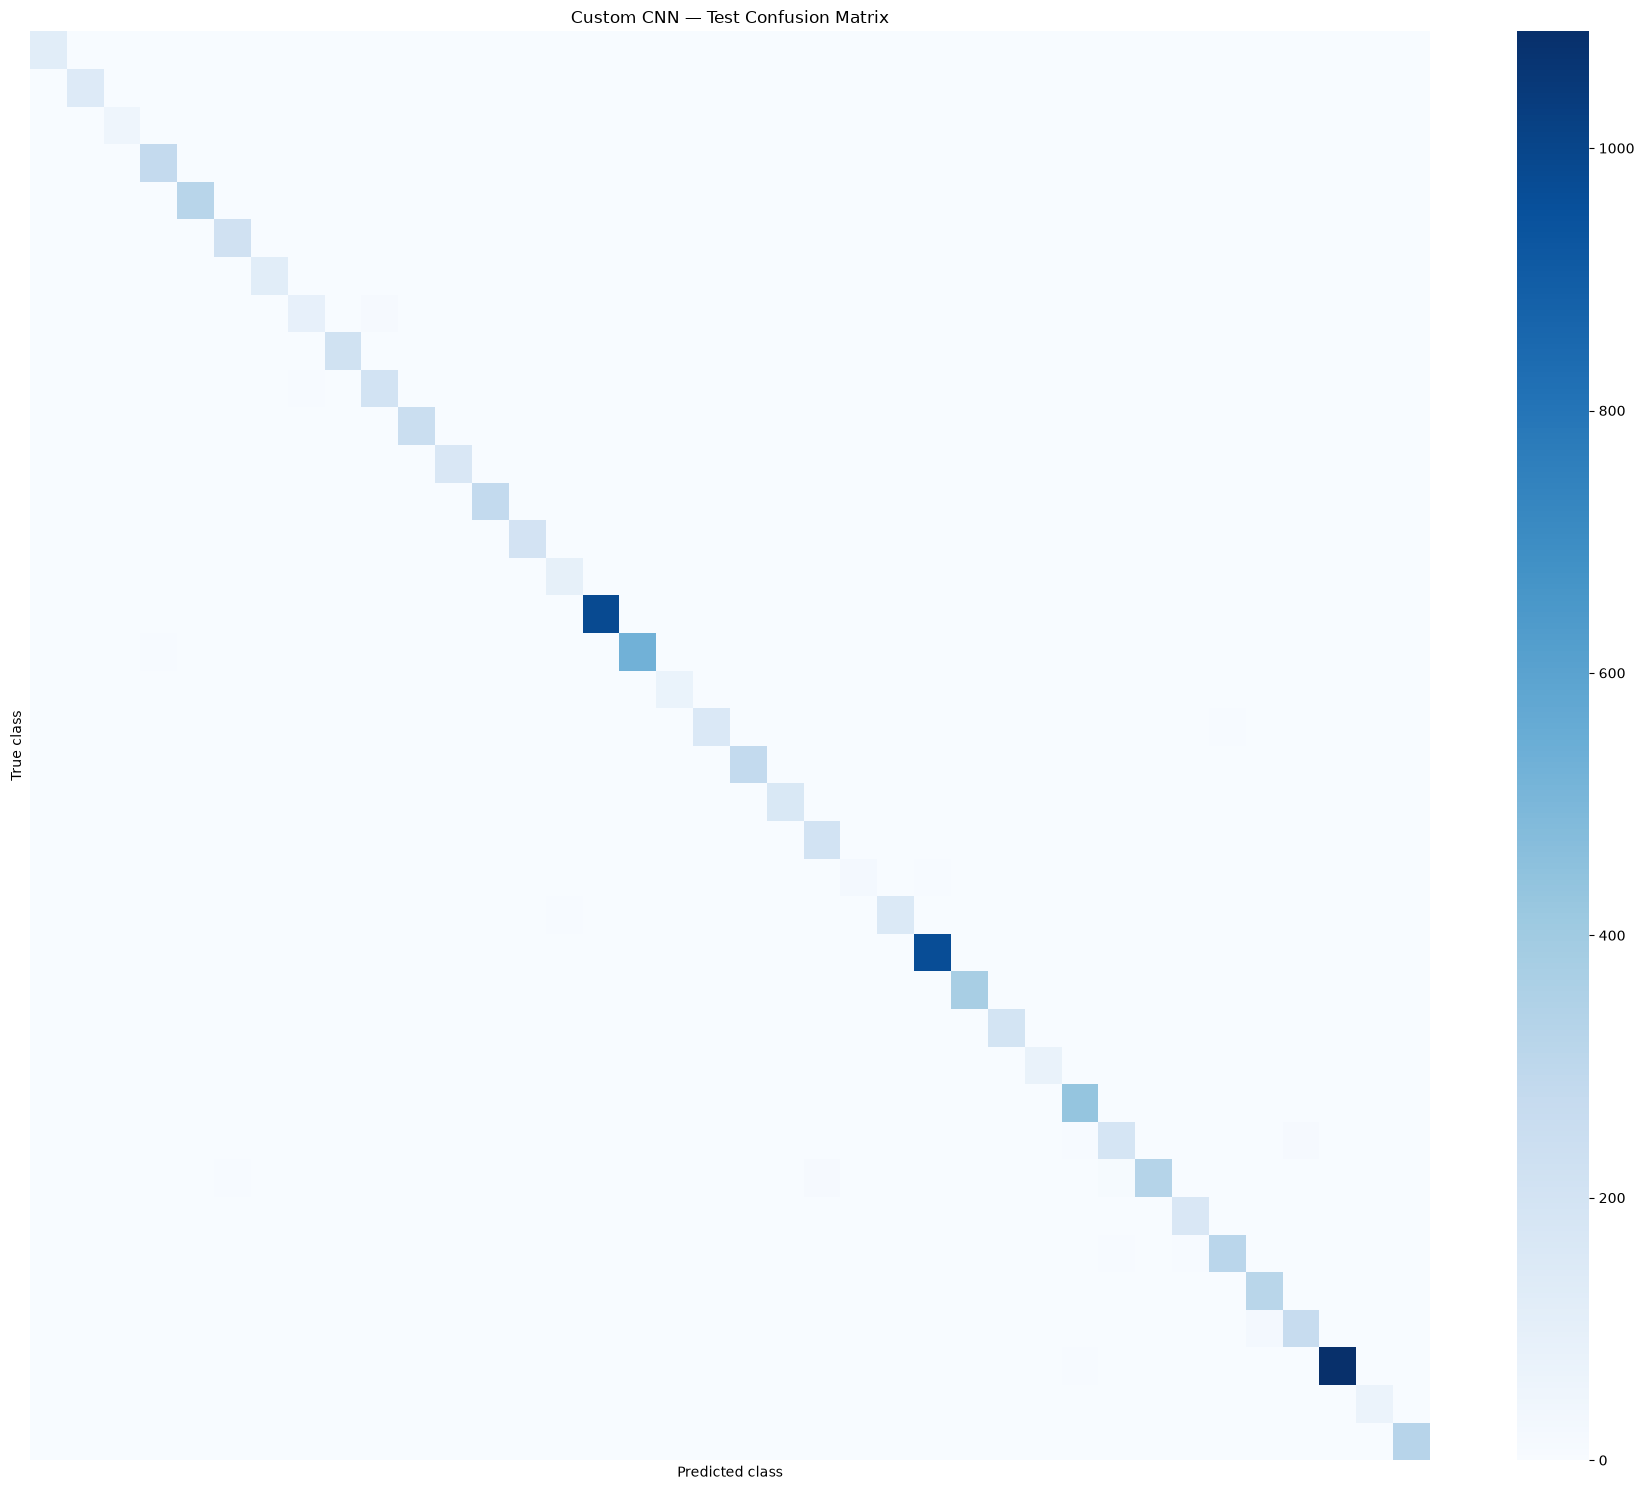

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print(f"Test accuracy:  {accuracy * 100:.2f}%")
print(f"Macro precision: {precision * 100:.2f}%")
print(f"Macro recall:    {recall * 100:.2f}%")
print(f"Macro F1-score:  {f1 * 100:.2f}%")
print("Test images evaluated:", len(all_labels))

class_names = [
    name for name, idx in sorted(
        class_to_idx.items(), key=lambda item: item[1]
    )
]

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_labels, all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(18, 15))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("Custom CNN — Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

In [1]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")

paths = {
    "Custom CNN history": PROJECT_DIR / "models" / "custom_cnn" / "training_history.csv",
    "ResNet18 history": PROJECT_DIR / "models" / "resnet18" / "training_history.csv",
}

for name, path in paths.items():
    print(f"{name}: {path.exists()}")
    if path.exists():
        print(f"  Path: {path}")

Custom CNN history: True
  Path: E:\PlantVillage\models\custom_cnn\training_history.csv
ResNet18 history: True
  Path: E:\PlantVillage\models\resnet18\training_history.csv


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")

cnn_path = PROJECT_DIR / "models" / "custom_cnn" / "training_history.csv"
resnet_path = PROJECT_DIR / "models" / "resnet18" / "training_history.csv"

cnn = pd.read_csv(cnn_path)
resnet = pd.read_csv(resnet_path)

print("Custom CNN columns:", cnn.columns.tolist())
print("ResNet18 columns:", resnet.columns.tolist())

# Display saved history to verify column names
display(cnn.head())
display(resnet.head())


Custom CNN columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'learning_rate', 'time_minutes']
ResNet18 columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'learning_rate', 'time_minutes']


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,time_minutes
0,2,0.768501,0.762769,0.362615,0.892661,0.001,13.831432
1,3,0.568200,0.821643,0.293680,0.909174,0.001,12.450451
2,4,0.465124,0.855439,0.235036,0.927064,0.001,12.469462
3,5,0.390440,0.877383,0.247612,0.920642,0.001,12.471409
4,6,0.336054,0.896243,0.149124,0.952294,0.001,12.417054


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,time_minutes
0,1,0.537958,0.870196,0.231077,0.931881,0.001,24.454067
1,2,0.210216,0.936895,0.177352,0.942431,0.001,17.001000
2,3,0.164556,0.949307,0.147848,0.953440,0.001,6.184936
3,4,0.146166,0.954557,0.137528,0.955963,0.001,6.335409
4,5,0.135038,0.955857,0.127377,0.956193,0.001,6.299682


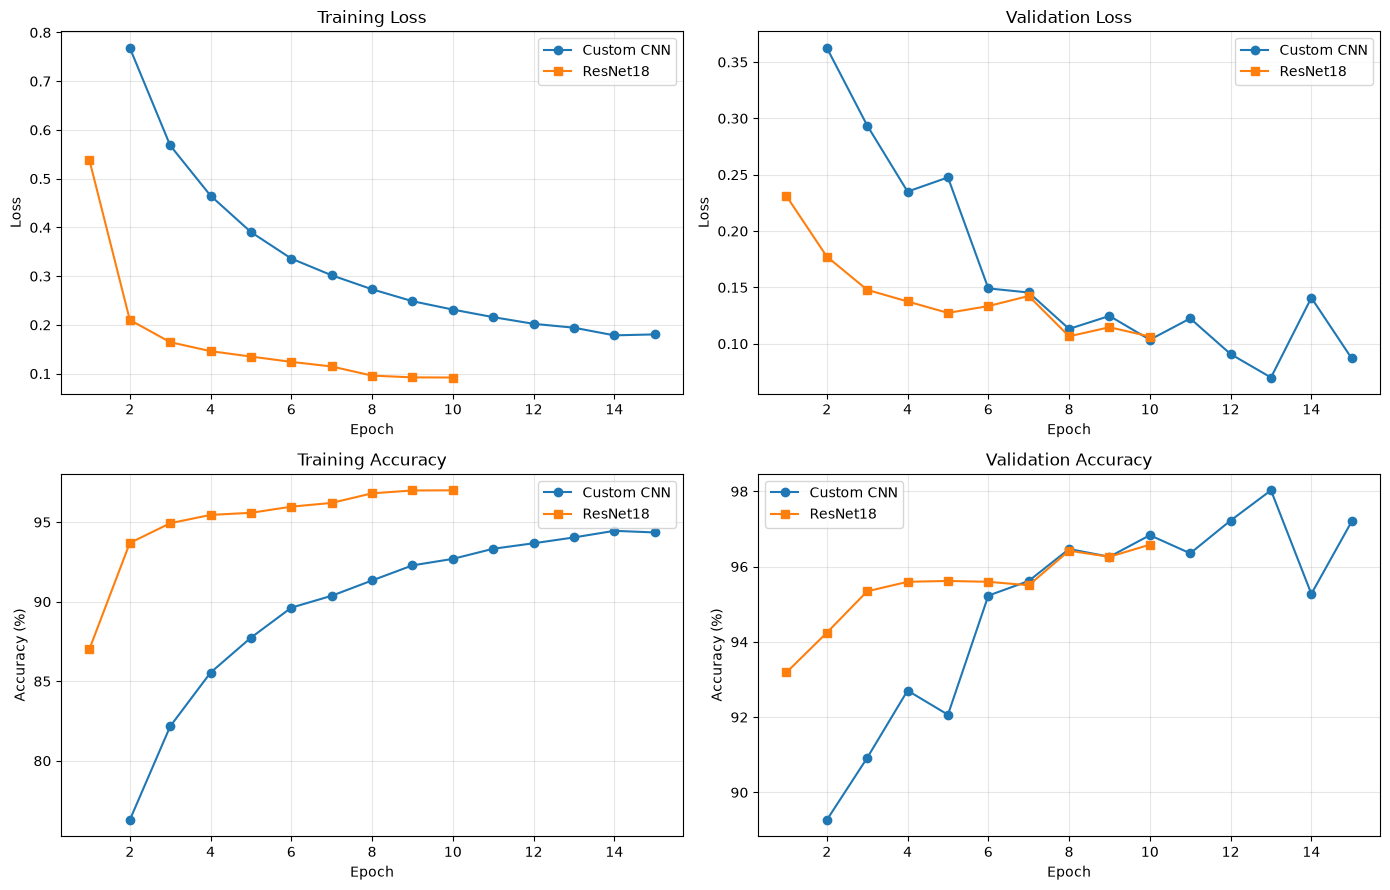

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Training loss
axes[0, 0].plot(cnn["epoch"], cnn["train_loss"], marker="o", label="Custom CNN")
axes[0, 0].plot(resnet["epoch"], resnet["train_loss"], marker="s", label="ResNet18")
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Validation loss
axes[0, 1].plot(cnn["epoch"], cnn["val_loss"], marker="o", label="Custom CNN")
axes[0, 1].plot(resnet["epoch"], resnet["val_loss"], marker="s", label="ResNet18")
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Training accuracy
axes[1, 0].plot(cnn["epoch"], cnn["train_accuracy"] * 100, marker="o", label="Custom CNN")
axes[1, 0].plot(resnet["epoch"], resnet["train_accuracy"] * 100, marker="s", label="ResNet18")
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Validation accuracy
axes[1, 1].plot(cnn["epoch"], cnn["val_accuracy"] * 100, marker="o", label="Custom CNN")
axes[1, 1].plot(resnet["epoch"], resnet["val_accuracy"] * 100, marker="s", label="ResNet18")
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy (%)")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [4]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Test Accuracy (%)": 97.73,
        "Macro Precision (%)": 97.21,
        "Macro Recall (%)": 96.65,
        "Macro F1-score (%)": 96.85,
    },
    {
        "Model": "ResNet18",
        "Test Accuracy (%)": 95.91,
        "Macro Precision (%)": 95.46,
        "Macro Recall (%)": 94.54,
        "Macro F1-score (%)": 94.90,
    },
])

display(comparison)

output_path = RESULTS_DIR / "model_comparison.csv"
comparison.to_csv(output_path, index=False)

print("Comparison saved to:", output_path)


,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%)
0,Custom CNN,97.73,97.21,96.65,96.85
1,ResNet18,95.91,95.46,94.54,94.90


Comparison saved to: E:\PlantVillage\results\model_comparison.csv


In [5]:

from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")

folders = [
    PROJECT_DIR / "models" / "custom_cnn",
    PROJECT_DIR / "models" / "resnet18",
    PROJECT_DIR / "results",
]

for folder in folders:
    print(f"\n{folder}")
    if folder.exists():
        for file in sorted(folder.iterdir()):
            if file.is_file():
                print(f"  {file.name} ({file.stat().st_size / 1024:.1f} KB)")
    else:
        print("  Folder not found")



E:\PlantVillage\models\custom_cnn
  best_model.pth (4708.5 KB)
  training_history.csv (1.5 KB)

E:\PlantVillage\models\resnet18
  best_resnet18.pth (43968.3 KB)
  training_history.csv (1.1 KB)

E:\PlantVillage\results
  model_comparison.csv (0.1 KB)


In [6]:

from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Existing files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)


Results directory: E:\PlantVillage\results
Existing files:
- model_comparison.csv


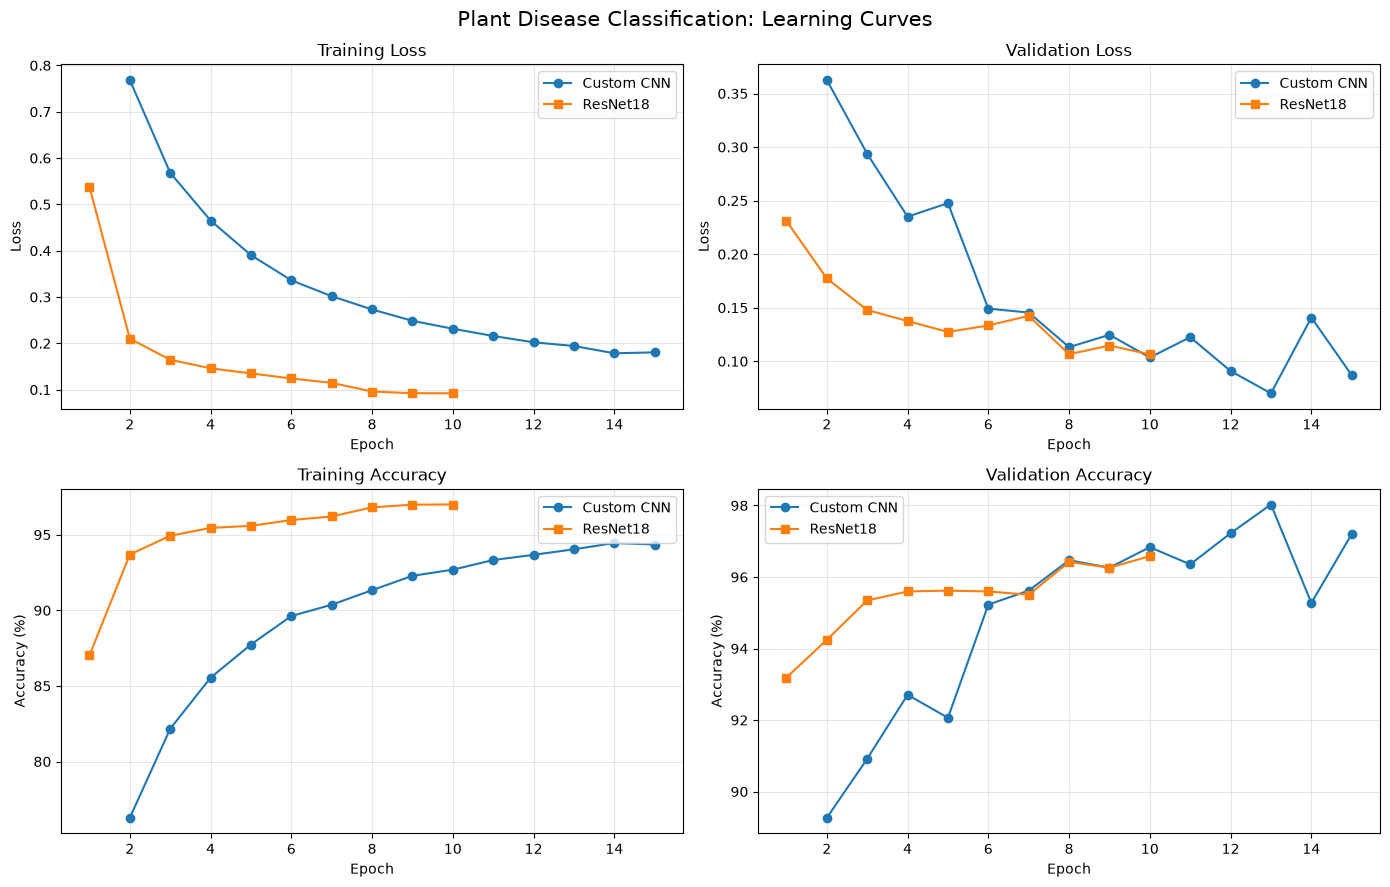

Learning curves saved to: E:\PlantVillage\results\learning_curves.png


In [7]:

import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    ("train_loss", "Training Loss", "Loss"),
    ("val_loss", "Validation Loss", "Loss"),
    ("train_accuracy", "Training Accuracy", "Accuracy (%)"),
    ("val_accuracy", "Validation Accuracy", "Accuracy (%)"),
]

for ax, (column, title, ylabel) in zip(axes.flat, plots):
    scale = 100 if "accuracy" in column else 1

    ax.plot(cnn["epoch"], cnn[column] * scale,
            marker="o", label="Custom CNN")
    ax.plot(resnet["epoch"], resnet[column] * scale,
            marker="s", label="ResNet18")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("Plant Disease Classification: Learning Curves",
             fontsize=15)
plt.tight_layout()

plot_path = RESULTS_DIR / "learning_curves.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Learning curves saved to:", plot_path)


In [8]:

names_to_check = [
    "y_true",
    "y_pred",
    "class_names",
    "test_labels",
    "test_predictions",
    "all_labels",
    "all_predictions",
]

for name in names_to_check:
    print(f"{name}: {'available' if name in globals() else 'missing'}")


y_true: missing
y_pred: missing
class_names: missing
test_labels: missing
test_predictions: missing
all_labels: missing
all_predictions: missing


In [9]:

from pathlib import Path
import torch
import torch.nn as nn
import pandas as pd
import numpy as np

PROJECT_DIR = Path(r"E:\PlantVillage")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

CUSTOM_CNN_CHECKPOINT = MODEL_DIR / "custom_cnn" / "best_model.pth"
RESNET_CHECKPOINT = MODEL_DIR / "resnet18" / "best_resnet18.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Custom CNN checkpoint exists:", CUSTOM_CNN_CHECKPOINT.exists())
print("ResNet18 checkpoint exists:", RESNET_CHECKPOINT.exists())


Device: cuda
Custom CNN checkpoint exists: True
ResNet18 checkpoint exists: True


In [22]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\PlantVillage")
RESULTS_DIR = PROJECT_DIR / "results"

print("Results directory:", RESULTS_DIR)
print("\nExisting result files:")

for path in sorted(RESULTS_DIR.glob("*")):
    if path.is_file():
        print(f"{path.name} ({path.stat().st_size / 1024:.1f} KB)")



Results directory: E:\PlantVillage\results

Existing result files:
learning_curves.png (402.1 KB)
model_comparison.csv (0.1 KB)


In [23]:
import pandas as pd
from pathlib import Path

comparison_path = Path(r"E:\PlantVillage\results\model_comparison.csv")

comparison_df = pd.read_csv(comparison_path)

print("Model comparison results:")
display(comparison_df)

print("\nColumns:", comparison_df.columns.tolist())


Model comparison results:


,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%)
0,Custom CNN,97.73,97.21,96.65,96.85
1,ResNet18,95.91,95.46,94.54,94.90



Columns: ['Model', 'Test Accuracy (%)', 'Macro Precision (%)', 'Macro Recall (%)', 'Macro F1-score (%)']


In [24]:
from pathlib import Path
import pandas as pd

project_dir = Path(r"E:\PlantVillage")
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(results_dir / "model_comparison.csv")

best_model = df.loc[df["Test Accuracy (%)"].idxmax()]

summary = f"""
PLANT DISEASE CLASSIFICATION — MODEL COMPARISON

Dataset: PlantVillage
Number of classes: 38
Test images: 10,704

{df.to_string(index=False)}

Best model by test accuracy: {best_model['Model']}
Test accuracy: {best_model['Test Accuracy (%)']:.2f}%
Macro precision: {best_model['Macro Precision (%)']:.2f}%
Macro recall: {best_model['Macro Recall (%)']:.2f}%
Macro F1-score: {best_model['Macro F1-score (%)']:.2f}%

Conclusion:
The Custom CNN achieved higher test accuracy, macro precision,
macro recall, and macro F1-score than ResNet18 in these experiments.
These results apply to the current dataset and training setup.
"""

summary_path = results_dir / "final_results_summary.txt"
summary_path.write_text(summary.strip(), encoding="utf-8")

print("Summary saved to:", summary_path)
print(summary)


Summary saved to: E:\PlantVillage\results\final_results_summary.txt

PLANT DISEASE CLASSIFICATION — MODEL COMPARISON

Dataset: PlantVillage
Number of classes: 38
Test images: 10,704

     Model  Test Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1-score (%)
Custom CNN              97.73                97.21             96.65               96.85
  ResNet18              95.91                95.46             94.54               94.90

Best model by test accuracy: Custom CNN
Test accuracy: 97.73%
Macro precision: 97.21%
Macro recall: 96.65%
Macro F1-score: 96.85%

Conclusion:
The Custom CNN achieved higher test accuracy, macro precision,
macro recall, and macro F1-score than ResNet18 in these experiments.
These results apply to the current dataset and training setup.

